# Giai đoạn 1: Khám phá dữ liệu RT-IoT2022
Notebook này chỉ đọc và phân tích dữ liệu. Chưa tiền xử lý để huấn luyện và chưa huấn luyện mô hình.

In [11]:
# Cài đặt thư viện và đọc dữ liệu từ thư mục notebooks
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
DATA_PATH = Path('../data/RT_IOT2022')
FIGURES_DIR = Path('../figures')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
df = pd.read_csv(DATA_PATH)
print(f'Đã đọc: {DATA_PATH}')
print('Kích thước:', df.shape)

Đã đọc: ..\data\RT_IOT2022
Kích thước: (123117, 85)


## 1. Tổng quan
Đọc dữ liệu, xem kích thước, tên cột, kiểu dữ liệu và vài dòng đầu. Số cột số/phân loại được tính từ kiểu dữ liệu thực tế, không giả định theo tài liệu.

In [12]:
# In thông tin cấu trúc bảng dữ liệu
print('Kích thước:', df.shape)
print('Tên cột:')
print(df.columns.tolist())
print('Kiểu dữ liệu:')
print(df.dtypes)
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()
print('Số cột số:', len(numeric_cols))
print('Số cột phân loại/không phải số:', len(categorical_cols))
display(df.head())

Kích thước: (123117, 85)
Tên cột:
['Unnamed: 0', 'id.orig_p', 'id.resp_p', 'proto', 'service', 'flow_duration', 'fwd_pkts_tot', 'bwd_pkts_tot', 'fwd_data_pkts_tot', 'bwd_data_pkts_tot', 'fwd_pkts_per_sec', 'bwd_pkts_per_sec', 'flow_pkts_per_sec', 'down_up_ratio', 'fwd_header_size_tot', 'fwd_header_size_min', 'fwd_header_size_max', 'bwd_header_size_tot', 'bwd_header_size_min', 'bwd_header_size_max', 'flow_FIN_flag_count', 'flow_SYN_flag_count', 'flow_RST_flag_count', 'fwd_PSH_flag_count', 'bwd_PSH_flag_count', 'flow_ACK_flag_count', 'fwd_URG_flag_count', 'bwd_URG_flag_count', 'flow_CWR_flag_count', 'flow_ECE_flag_count', 'fwd_pkts_payload.min', 'fwd_pkts_payload.max', 'fwd_pkts_payload.tot', 'fwd_pkts_payload.avg', 'fwd_pkts_payload.std', 'bwd_pkts_payload.min', 'bwd_pkts_payload.max', 'bwd_pkts_payload.tot', 'bwd_pkts_payload.avg', 'bwd_pkts_payload.std', 'flow_pkts_payload.min', 'flow_pkts_payload.max', 'flow_pkts_payload.tot', 'flow_pkts_payload.avg', 'flow_pkts_payload.std', 'fwd_ia

,Unnamed: 0,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,bwd_pkts_per_sec,flow_pkts_per_sec,down_up_ratio,fwd_header_size_tot,fwd_header_size_min,fwd_header_size_max,bwd_header_size_tot,bwd_header_size_min,bwd_header_size_max,flow_FIN_flag_count,flow_SYN_flag_count,flow_RST_flag_count,fwd_PSH_flag_count,bwd_PSH_flag_count,flow_ACK_flag_count,fwd_URG_flag_count,bwd_URG_flag_count,flow_CWR_flag_count,flow_ECE_flag_count,fwd_pkts_payload.min,fwd_pkts_payload.max,fwd_pkts_payload.tot,fwd_pkts_payload.avg,fwd_pkts_payload.std,bwd_pkts_payload.min,bwd_pkts_payload.max,bwd_pkts_payload.tot,bwd_pkts_payload.avg,bwd_pkts_payload.std,flow_pkts_payload.min,flow_pkts_payload.max,flow_pkts_payload.tot,flow_pkts_payload.avg,flow_pkts_payload.std,fwd_iat.min,fwd_iat.max,fwd_iat.tot,fwd_iat.avg,fwd_iat.std,bwd_iat.min,bwd_iat.max,bwd_iat.tot,bwd_iat.avg,bwd_iat.std,flow_iat.min,flow_iat.max,flow_iat.tot,flow_iat.avg,flow_iat.std,payload_bytes_per_second,fwd_subflow_pkts,bwd_subflow_pkts,fwd_subflow_bytes,bwd_subflow_bytes,fwd_bulk_bytes,bwd_bulk_bytes,fwd_bulk_packets,bwd_bulk_packets,fwd_bulk_rate,bwd_bulk_rate,active.min,active.max,active.tot,active.avg,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,0,38667,1883,tcp,mqtt,32.011598,9,5,3,3,0.281148,0.156193,0.437341,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,76.0,8.444444,13.115936,0.0,23.0,32.0,6.4,9.555103,0.0,33.0,108.0,7.714286,11.618477,761.985779,2.972918e+07,3.201160e+07,4.001450e+06,1.040307e+07,4438.877106,1.511694e+06,2.026391e+06,506597.757339,680406.147126,761.985779,2.972918e+07,3.201160e+07,2.462431e+06,8.199747e+06,3.373777,3.0,1.666667,25.333333,10.666667,0.0,0.0,0.0,0.0,0.0,0.0,2.282415e+06,2.282415e+06,2.282415e+06,2.282415e+06,0.0,2.972918e+07,2.972918e+07,2.972918e+07,2.972918e+07,0.0,64240,26847,502,MQTT_Publish
1,1,51143,1883,tcp,mqtt,31.883584,9,5,3,3,0.282277,0.156821,0.439097,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,76.0,8.444444,13.115936,0.0,23.0,32.0,6.4,9.555103,0.0,33.0,108.0,7.714286,11.618477,247.001648,2.985528e+07,3.188358e+07,3.985448e+06,1.046346e+07,4214.048386,1.576436e+06,1.876261e+06,469065.248966,741351.686212,247.001648,2.985528e+07,3.188358e+07,2.452583e+06,8.242459e+06,3.387323,3.0,1.666667,25.333333,10.666667,0.0,0.0,0.0,0.0,0.0,0.0,2.028307e+06,2.028307e+06,2.028307e+06,2.028307e+06,0.0,2.985528e+07,2.985528e+07,2.985528e+07,2.985528e+07,0.0,64240,26847,502,MQTT_Publish
2,2,44761,1883,tcp,mqtt,32.124053,9,5,3,3,0.280164,0.155647,0.435811,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,74.0,8.222222,12.852799,0.0,21.0,30.0,6.0,8.689074,0.0,33.0,104.0,7.428571,11.229866,283.956528,2.984215e+07,3.212405e+07,4.015507e+06,1.044238e+07,2456.903458,1.476049e+06,2.013770e+06,503442.466259,660344.360027,283.956528,2.984215e+07,3.212405e+07,2.471081e+06,8.230593e+06,3.237450,3.0,1.666667,24.666667,10.000000,0.0,0.0,0.0,0.0,0.0,0.0,2.281904e+06,2.281904e+06,2.281904e+06,2.281904e+06,0.0,2.984215e+07,2.984215e+07,2.984215e+07,2.984215e+07,0.0,64240,26847,502,MQTT_Publish
3,3,60893,1883,tcp,mqtt,31.961063,9,5,3,3,0.281593,0.156440,0.438033,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,74.0,8.222222,12.852799,0.0,21.0,30.0,6.0,8.689074,0.0,33.0,104.0,7.428571,11.229866,288.963318,2.991377e+07,3.196106e+07,3.995133e+06,1.048253e+07,3933.906555,1.551892e+06,1.883784e+06,470946.013927,724569.317911,288.963318,2.991377e+07,3.196106e+07,2.458543e+06,8.257786e+06,3.253959,3.0,1.666667,24.666667,10.000000,0.0,0.0,0.0,0.0,0.0,0.0,2.047288e+06,2.047288e+06,2.047288e+06,2.047288e+06,0.0,2.991377e+07,2.991377e+07,2.991377e+07,2.991377e+07,0.0,64240,26847,502,MQTT_Publish
4,4,51087,1883,tcp,mqtt,31.902362,9,5,3,3,0.282111,0.156728,0.438839,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,76.0,8.444444,13.115936,0.0,23.0,32.0,6.4,9.555103,0.

## 2. Chất lượng dữ liệu
Kiểm tra thiếu, cột hằng, bản ghi trùng và các cột có vẻ chỉ là chỉ số. Chưa xóa hay thay đổi dữ liệu gốc.

In [13]:
# Kiểm tra thiếu, hằng, trùng lặp và cột chỉ số
missing = df.isna().sum().sort_values(ascending=False)
print('Cột có giá trị thiếu:')
display(missing[missing > 0].to_frame('so_gia_tri_thieu'))
constant_cols = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
print('Cột hằng:', constant_cols)
print('Số bản ghi trùng toàn bộ cột:', int(df.duplicated().sum()))
index_like_cols = [c for c in df.columns if c.lower().startswith('unnamed') or c.lower() in {'index', 'id'}]
print('Cột nghi là cột chỉ số:', index_like_cols)
for c in index_like_cols:
    print(f'Trùng khi bỏ {c}:', int(df.drop(columns=c).duplicated().sum()))

Cột có giá trị thiếu:


,so_gia_tri_thieu


Cột hằng: ['bwd_URG_flag_count']
Số bản ghi trùng toàn bộ cột: 0
Cột nghi là cột chỉ số: ['Unnamed: 0']
Trùng khi bỏ Unnamed: 0: 5195


## 3. Phân bố nhãn `Attack_type`
Bảng đếm và phần trăm giúp thấy mức mất cân bằng. Hai biểu đồ dùng cùng dữ liệu: một thang tuyến tính và một thang log để nhìn rõ lớp nhỏ.

,so_luong,phan_tram
Attack_type,,
DOS_SYN_Hping,94659,76.885402
Thing_Speak,8108,6.585606
ARP_poisioning,7750,6.294825
MQTT_Publish,4146,3.367528
NMAP_UDP_SCAN,2590,2.103690
NMAP_XMAS_TREE_SCAN,2010,1.632593
NMAP_OS_DETECTION,2000,1.624471
NMAP_TCP_scan,1002,0.813860
DDOS_Slowloris,534,0.433734


Tỷ lệ lớp lớn nhất/nhỏ nhất: 3380.6785714285716


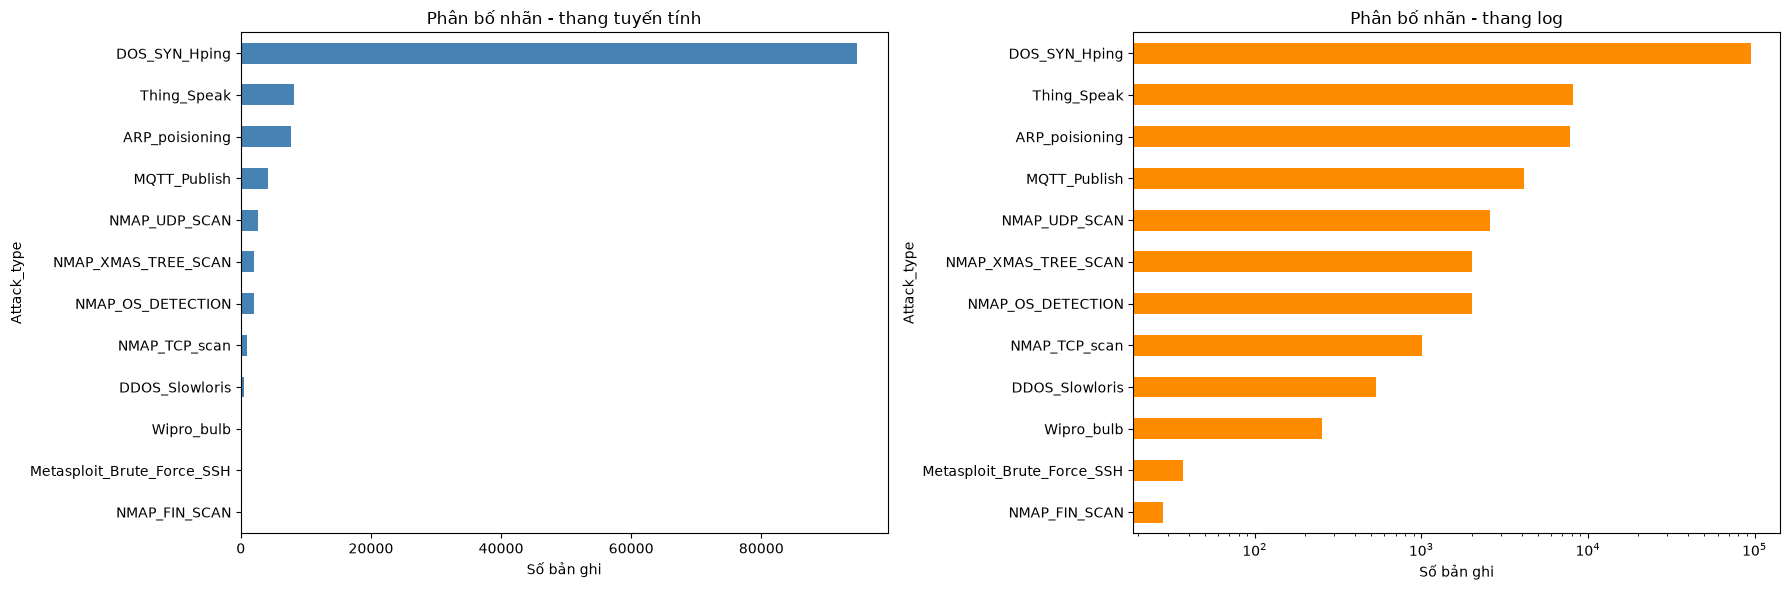

In [14]:
# Tính bảng phân bố nhãn và vẽ hai thang đo
label_counts = df['Attack_type'].value_counts()
label_table = pd.DataFrame({'so_luong': label_counts, 'phan_tram': label_counts / len(df) * 100})
display(label_table)
print('Tỷ lệ lớp lớn nhất/nhỏ nhất:', label_counts.max() / label_counts.min())
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
label_counts.sort_values().plot.barh(ax=axes[0], color='steelblue', title='Phân bố nhãn - thang tuyến tính')
label_counts.sort_values().plot.barh(ax=axes[1], color='darkorange', logx=True, title='Phân bố nhãn - thang log')
for ax in axes: ax.set_xlabel('Số bản ghi'); ax.set_ylabel('Attack_type')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '01_phan_bo_nhan_linear_log.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Ánh xạ nhị phân đề xuất
Bảng dưới đây chỉ là đề xuất nhãn cho thí nghiệm phụ. Dữ liệu `df` chưa bị thay đổi và chưa tạo cột mới.

In [15]:
# Tạo bảng ánh xạ để quan sát, không áp dụng vào df
normal_labels = {'Thing_Speak', 'MQTT_Publish', 'Wipro_bulb'}
mapping_table = pd.DataFrame({'Attack_type': label_counts.index})
mapping_table['nhom_de_xuat'] = mapping_table['Attack_type'].map(lambda x: 'bình thường' if x in normal_labels else 'tấn công')
display(mapping_table.sort_values(['nhom_de_xuat', 'Attack_type']).reset_index(drop=True))

,Attack_type,nhom_de_xuat
0,MQTT_Publish,bình thường
1,Thing_Speak,bình thường
2,Wipro_bulb,bình thường
3,ARP_poisioning,tấn công
4,DDOS_Slowloris,tấn công
5,DOS_SYN_Hping,tấn công
6,Metasploit_Brute_Force_SSH,tấn công
7,NMAP_FIN_SCAN,tấn công
8,NMAP_OS_DETECTION,tấn công
9,NMAP_TCP_scan,tấn công


## 5. Cột nghi rò rỉ: `id.orig_p`, `id.resp_p`
Tỷ lệ dưới đây là tỷ lệ giá trị cổng mà chỉ xuất hiện trong đúng một lớp. Tỷ lệ cao là dấu hiệu cần thí nghiệm có/không có cột này ở giai đoạn sau, chưa đủ để kết luận phải xóa ngay.

In [16]:
# Phân tích độ đặc hiệu của cổng theo lớp nhãn
def port_report(column):
    if column not in df.columns:
        print(f'Không có cột {column}')
        return
    n_values = df[column].nunique(dropna=False)
    port_classes = df.groupby(column, dropna=False)['Attack_type'].nunique()
    single_class_rate = (port_classes == 1).mean() * 100
    print(f'{column}: {n_values} giá trị khác nhau; {single_class_rate:.2f}% giá trị chỉ xuất hiện trong đúng một lớp')
    top = (df.groupby(['Attack_type', column], dropna=False).size().rename('so_luong')
           .reset_index().sort_values(['Attack_type', 'so_luong'], ascending=[True, False])
           .groupby('Attack_type', sort=False).head(10))
    display(top)
for port_col in ['id.orig_p', 'id.resp_p']:
    port_report(port_col)

id.orig_p: 65478 giá trị khác nhau; 76.74% giá trị chỉ xuất hiện trong đúng một lớp


,Attack_type,id.orig_p,so_luong
5,ARP_poisioning,5353,99
3,ARP_poisioning,68,26
262,ARP_poisioning,33802,13
4383,ARP_poisioning,52136,6
4408,ARP_poisioning,52216,6
...,...,...,...
84219,Wipro_bulb,3,2
84223,Wipro_bulb,3716,2
84226,Wipro_bulb,6334,2
84230,Wipro_bulb,8886,2


id.resp_p: 1809 giá trị khác nhau; 44.28% giá trị chỉ xuất hiện trong đúng một lớp


,Attack_type,id.resp_p,so_luong
3,ARP_poisioning,53,3166
10,ARP_poisioning,5353,2036
9,ARP_poisioning,443,1957
8,ARP_poisioning,137,381
5,ARP_poisioning,80,167
4,ARP_poisioning,67,26
6,ARP_poisioning,123,7
0,ARP_poisioning,0,3
1,ARP_poisioning,3,2
2,ARP_poisioning,8,2


## 6. Đặc trưng phân loại
Liệt kê các cột kiểu chữ/không phải số, số giá trị khác nhau và tối đa 10 giá trị phổ biến. Điều này giúp chọn cách mã hóa ở giai đoạn 2.

In [17]:
# Tóm tắt các cột phân loại
for col in categorical_cols:
    print(f'\n{col}: {df[col].nunique(dropna=False)} giá trị khác nhau')
    display(df[col].value_counts(dropna=False).head(10).rename('so_luong').to_frame())


proto: 3 giá trị khác nhau


,so_luong
proto,
tcp,110427
udp,12633
icmp,57



service: 10 giá trị khác nhau


,so_luong
service,
-,102861
dns,9753
mqtt,4132
http,3464
ssl,2663
ntp,121
dhcp,50
irc,43
ssh,28



Attack_type: 12 giá trị khác nhau


,so_luong
Attack_type,
DOS_SYN_Hping,94659
Thing_Speak,8108
ARP_poisioning,7750
MQTT_Publish,4146
NMAP_UDP_SCAN,2590
NMAP_XMAS_TREE_SCAN,2010
NMAP_OS_DETECTION,2000
NMAP_TCP_scan,1002
DDOS_Slowloris,534


## 7. Thống kê mô tả và phân phối
Thống kê số được giữ nguyên để quan sát ngoại lệ. Notebook tự chọn tối đa 8 cột tiêu biểu dựa trên tên cột thực tế; nếu tên không khớp, sẽ dùng các cột số đầu tiên. Boxplot dùng trục log khi dữ liệu không âm và có độ lệch lớn.

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,123117.0,3.703509e+04,3.045911e+04,0.0,6059.000000,3.310000e+04,6.387900e+04,9.465800e+04
id.orig_p,123117.0,3.463926e+04,1.907062e+04,0.0,17702.000000,3.722100e+04,5.097100e+04,6.553500e+04
id.resp_p,123117.0,1.014305e+03,5.256372e+03,0.0,21.000000,2.100000e+01,2.100000e+01,6.538900e+04
flow_duration,123117.0,3.809566e+00,1.300054e+02,0.0,0.000001,4.000000e-06,5.000000e-06,2.172834e+04
fwd_pkts_tot,123117.0,2.268826e+00,2.233656e+01,0.0,1.000000,1.000000e+00,1.000000e+00,4.345000e+03
bwd_pkts_tot,123117.0,1.909509e+00,3.301831e+01,0.0,1.000000,1.000000e+00,1.000000e+00,1.011200e+04
fwd_data_pkts_tot,123117.0,1.471218e+00,1.963520e+01,0.0,1.000000,1.000000e+00,1.000000e+00,4.345000e+03
bwd_data_pkts_tot,123117.0,8.202604e-01,3.229395e+01,0.0,0.000000,0.000000e+00,0.000000e+00,1.010500e+04
fwd_pkts_per_sec,123117.0,3.518063e+05,3.707645e+05,0.0,74.543538,2.467238e+05,5.242880e+05,1.048576e+06
bwd_pkts_per_sec,123117.0,3.517620e+05,3.708015e+05,0.0,72.889275,2.467238e+05,5.242880e+05,1.048576e+06


Đặc trưng được chọn: ['flow_duration', 'fwd_pkts_tot', 'bwd_pkts_tot', 'fwd_data_pkts_tot', 'bwd_data_pkts_tot', 'fwd_pkts_per_sec', 'bwd_pkts_per_sec', 'flow_pkts_per_sec']


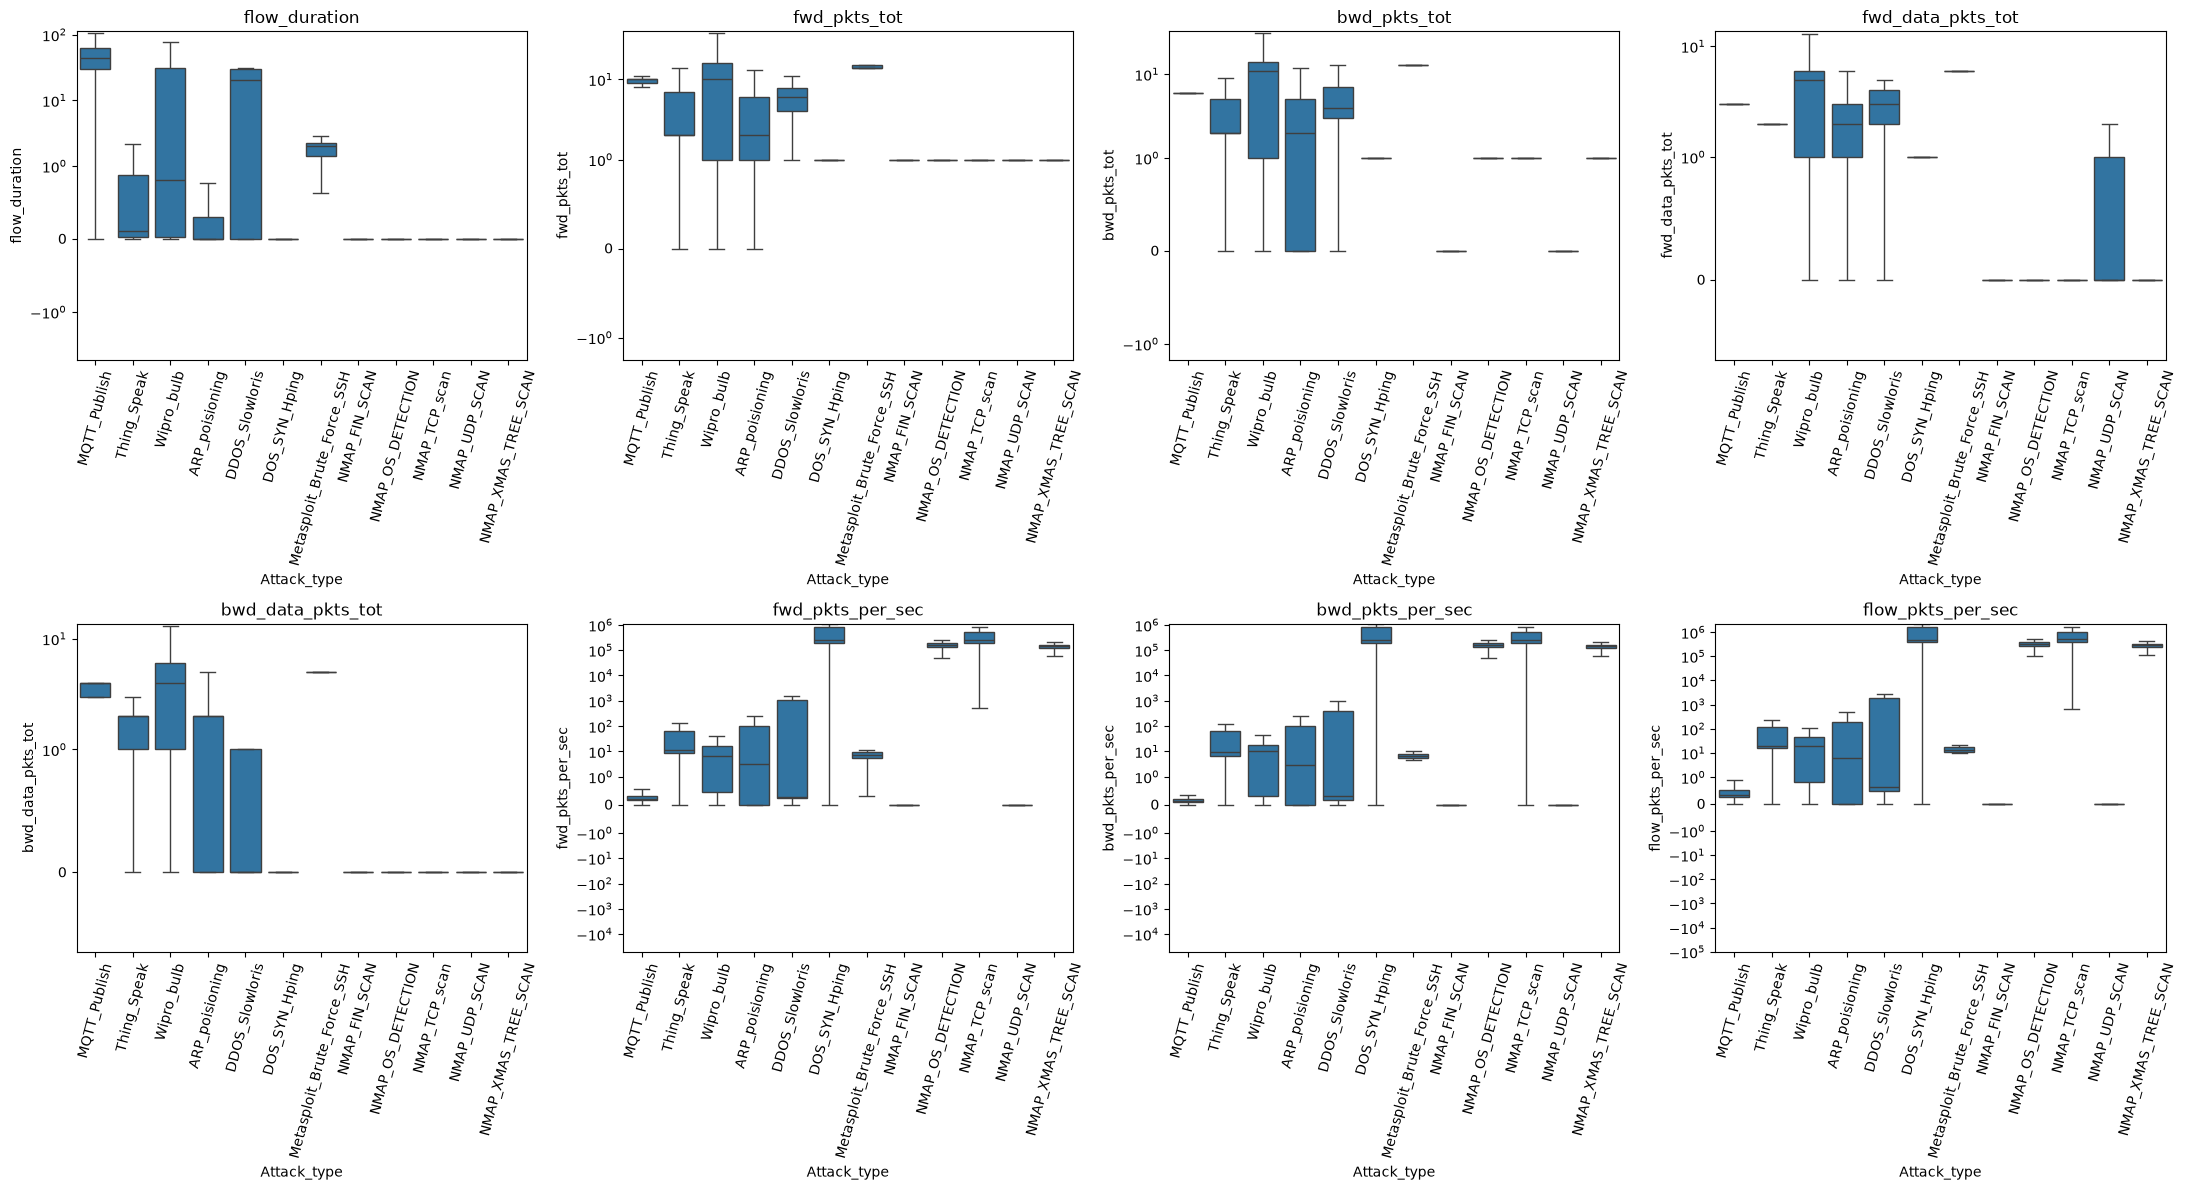

Ghi chú: showfliers=False chỉ làm biểu đồ dễ đọc; không xóa ngoại lệ khỏi df.


In [18]:
# Thống kê mô tả và chọn đặc trưng số tiêu biểu
display(df[numeric_cols].describe().T)
keywords = ['flow', 'time', 'dur', 'pkt', 'packet', 'byte', 'payload', 'syn', 'ack', 'fin', 'rst', 'psh', 'urg']
representative = [c for c in numeric_cols if any(k in c.lower() for k in keywords)][:8]
if len(representative) < 8:
    representative += [c for c in numeric_cols if c not in representative][:8-len(representative)]
print('Đặc trưng được chọn:', representative)
plot_df = df[representative + ['Attack_type']].copy()
fig, axes = plt.subplots(2, 4, figsize=(22, 12))
for ax, col in zip(axes.flat, representative):
    sns.boxplot(data=plot_df, x='Attack_type', y=col, ax=ax, showfliers=False)
    ax.set_title(col); ax.tick_params(axis='x', rotation=75)
    if plot_df[col].min() >= 0 and plot_df[col].max() / (plot_df[col].replace(0, np.nan).min() or 1) > 100:
        ax.set_yscale('symlog', linthresh=1)
for ax in axes.flat[len(representative):]: ax.set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '02_boxplot_dac_trung_theo_lop.png', dpi=150, bbox_inches='tight')
plt.show()
print('Ghi chú: showfliers=False chỉ làm biểu đồ dễ đọc; không xóa ngoại lệ khỏi df.')

## 8. Tương quan
Ma trận tương quan Pearson chỉ dùng các cột số. Các cặp có `|r| > 0,95` là ứng viên cần xem xét loại bớt ở giai đoạn 2, nhưng quyết định cuối cùng phải dựa trên pipeline và kết quả thực nghiệm.

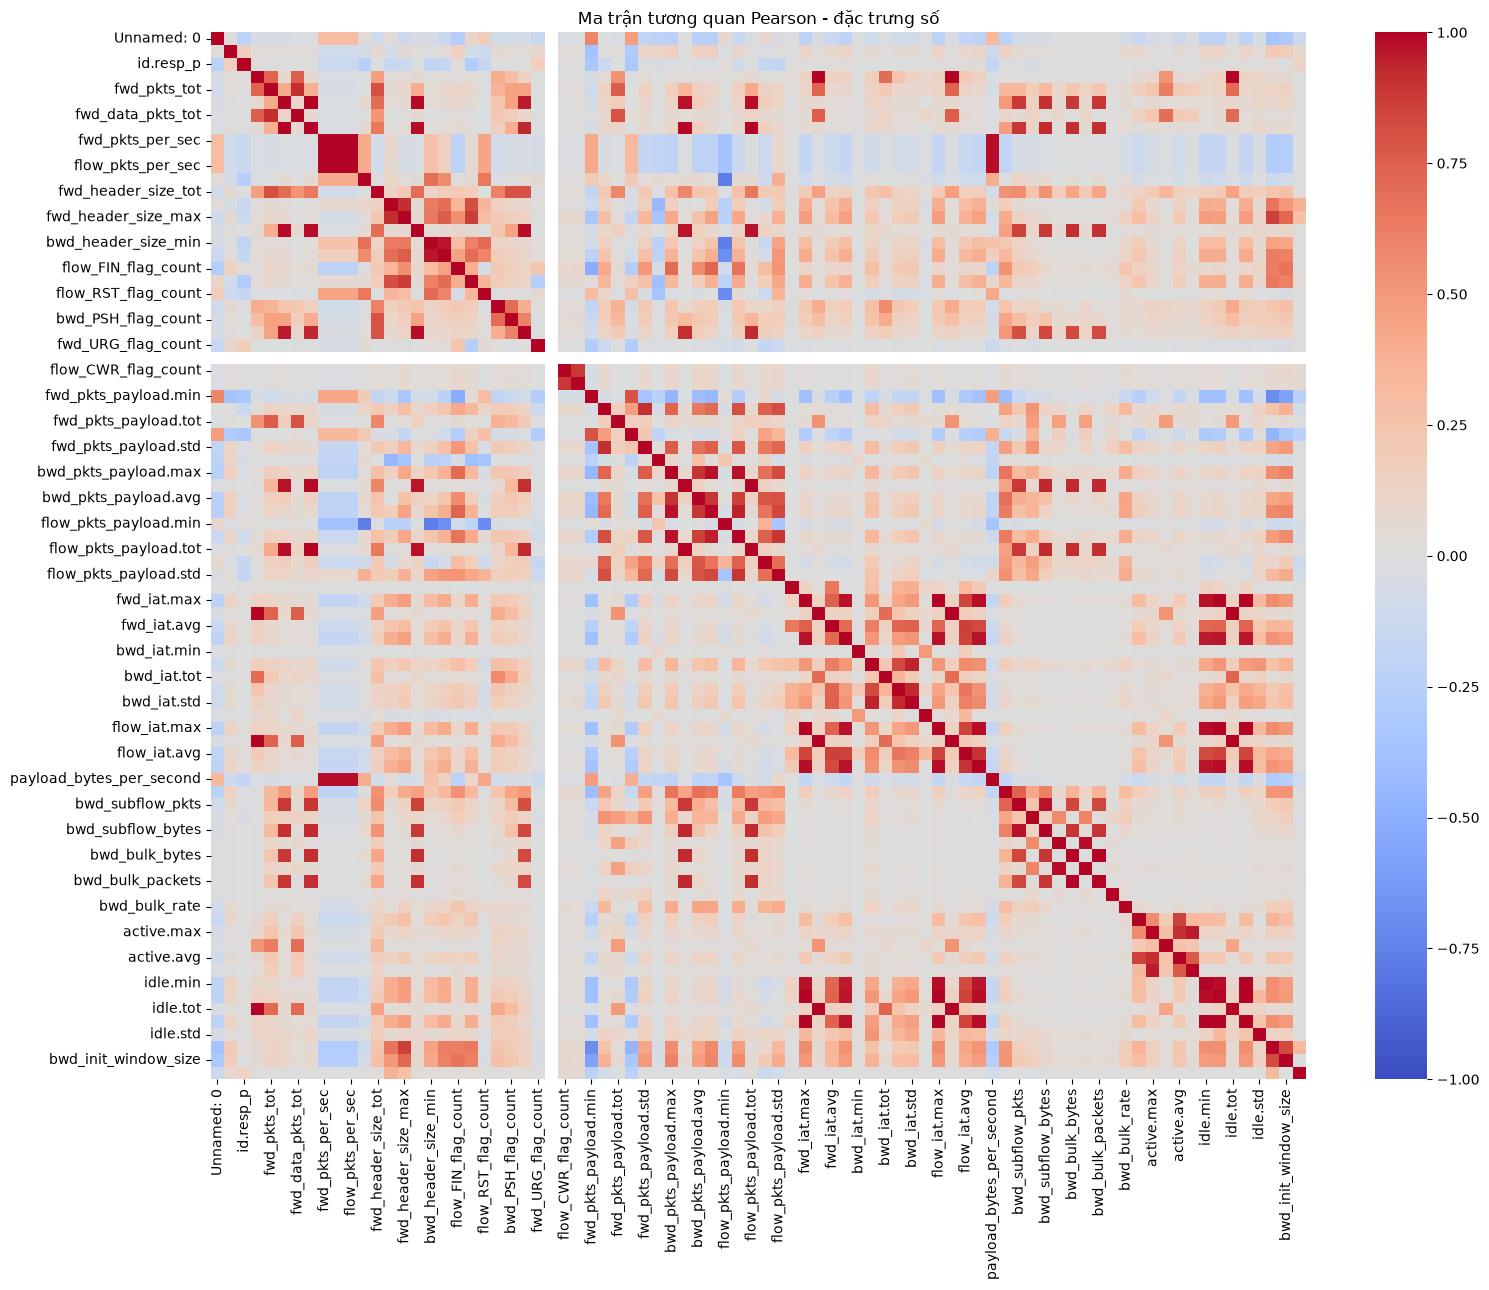

,cot_1,cot_2,r,abs_r
1,flow_duration,flow_iat.tot,1.000000,1.000000
14,bwd_pkts_per_sec,flow_pkts_per_sec,0.999997,0.999997
12,fwd_pkts_per_sec,flow_pkts_per_sec,0.999997,0.999997
11,fwd_pkts_per_sec,bwd_pkts_per_sec,0.999986,0.999986
47,bwd_bulk_bytes,bwd_bulk_packets,0.999802,0.999802
39,flow_iat.max,idle.max,0.999748,0.999748
30,fwd_iat.tot,flow_iat.tot,0.999719,0.999719
0,flow_duration,fwd_iat.tot,0.999719,0.999719
25,fwd_iat.max,flow_iat.max,0.996647,0.996647
28,fwd_iat.max,idle.max,0.996389,0.996389


In [19]:
# Vẽ heatmap và liệt kê cặp tương quan rất cao
corr = df[numeric_cols].corr()
plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Ma trận tương quan Pearson - đặc trưng số')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '03_heatmap_tuong_quan.png', dpi=150, bbox_inches='tight')
plt.show()
high_corr = []
for i, c1 in enumerate(corr.columns):
    for c2 in corr.columns[i+1:]:
        r = corr.loc[c1, c2]
        if abs(r) > 0.95:
            high_corr.append({'cot_1': c1, 'cot_2': c2, 'r': r, 'abs_r': abs(r)})
high_corr = pd.DataFrame(high_corr).sort_values('abs_r', ascending=False)
display(high_corr)

## 9. Tổng kết Giai đoạn 1
Ô này tự in các số liệu đã tính từ dữ liệu. Các đề xuất tiền xử lý chỉ là kế hoạch cho Giai đoạn 2, chưa thực hiện trong notebook này.

In [20]:
# In tổng kết bằng các kết quả thực tế đã tính ở các ô trước
print('=== TỔNG KẾT GIAI ĐOẠN 1 ===')
print(f'1. Dữ liệu có {df.shape[0]:,} dòng và {df.shape[1]} cột.')
print(f"2. Nhãn có {df['Attack_type'].nunique()} lớp; lớp lớn nhất: {label_counts.index[0]} ({label_counts.iloc[0]:,} mẫu), lớp nhỏ nhất: {label_counts.index[-1]} ({label_counts.iloc[-1]:,} mẫu).")
print(f'3. Tỷ lệ lớp lớn nhất/nhỏ nhất: {label_counts.max() / label_counts.min():.2f}.')
print(f'4. Tổng số giá trị thiếu: {int(df.isna().sum().sum())}; số cột hằng: {len(constant_cols)}; trùng toàn bộ: {int(df.duplicated().sum())}.')
print('5. Phát hiện cần chú ý: xem bảng cổng, cột phân loại, boxplot và high_corr ở trên để nhận diện nguy cơ rò rỉ, lệch phân phối, ngoại lệ và dư thừa.')
print('=== ĐỀ XUẤT CHO GIAI ĐOẠN 2 ===')
print('- Nếu có cột chỉ số/cột hằng: cân nhắc loại trước khi chia dữ liệu vì không mang tín hiệu dự đoán hữu ích.')
print('- Nếu có bản ghi trùng: cân nhắc xử lý trước khi chia để tránh cùng một flow xuất hiện ở train và test.')
print('- Với mất cân bằng: dùng stratify và so sánh class_weight/SMOTE chỉ trong phần train; chọn Macro-F1 và recall lớp hiếm.')
print('- Với cổng có tính đặc hiệu cao: chạy thí nghiệm có và không có id.orig_p/id.resp_p để kiểm tra rò rỉ.')
print('- Với cặp |r| > 0.95: cân nhắc loại một cột trong pipeline và so sánh kết quả, không xóa dữ liệu gốc.')
print('- Với biến phân loại: chọn One-Hot hoặc Ordinal dựa trên số lượng giá trị khác nhau ở bảng phần 6.')

=== TỔNG KẾT GIAI ĐOẠN 1 ===
1. Dữ liệu có 123,117 dòng và 85 cột.
2. Nhãn có 12 lớp; lớp lớn nhất: DOS_SYN_Hping (94,659 mẫu), lớp nhỏ nhất: NMAP_FIN_SCAN (28 mẫu).
3. Tỷ lệ lớp lớn nhất/nhỏ nhất: 3380.68.
4. Tổng số giá trị thiếu: 0; số cột hằng: 1; trùng toàn bộ: 0.
5. Phát hiện cần chú ý: xem bảng cổng, cột phân loại, boxplot và high_corr ở trên để nhận diện nguy cơ rò rỉ, lệch phân phối, ngoại lệ và dư thừa.
=== ĐỀ XUẤT CHO GIAI ĐOẠN 2 ===
- Nếu có cột chỉ số/cột hằng: cân nhắc loại trước khi chia dữ liệu vì không mang tín hiệu dự đoán hữu ích.
- Nếu có bản ghi trùng: cân nhắc xử lý trước khi chia để tránh cùng một flow xuất hiện ở train và test.
- Với mất cân bằng: dùng stratify và so sánh class_weight/SMOTE chỉ trong phần train; chọn Macro-F1 và recall lớp hiếm.
- Với cổng có tính đặc hiệu cao: chạy thí nghiệm có và không có id.orig_p/id.resp_p để kiểm tra rò rỉ.
- Với cặp |r| > 0.95: cân nhắc loại một cột trong pipeline và so sánh kết quả, không xóa dữ liệu gốc.
- Với biến phân

In [21]:
import pandas as pd
df = pd.read_csv('../data/RT_IOT2022')
print("5 cột đầu:", df.columns[:5].tolist())

# Cột hằng và cột nghi là chỉ số
const = [c for c in df.columns if df[c].nunique() == 1]
print("Cột hằng:", const)
idx = [c for c in df.columns
       if c.lower().startswith('unnamed')
       or (df[c].is_unique and pd.api.types.is_integer_dtype(df[c]))]
print("Cột nghi là chỉ số:", idx)

# Bản ghi trùng sau khi bỏ cột chỉ số
feat = df.drop(columns=idx, errors='ignore')
print("Trùng (kể cả nhãn):", feat.duplicated().sum())
print("Trùng (chỉ xét đặc trưng, không xét nhãn):",
      feat.drop(columns=['Attack_type']).duplicated().sum())

# Mức tiết lộ nhãn của cột cổng
for p in ['id.orig_p', 'id.resp_p']:
    g = df.groupby(p)['Attack_type'].nunique()
    print(p, "| số cổng khác nhau:", len(g),
          "| tỷ lệ cổng chỉ thuộc 1 lớp:", round((g == 1).mean(), 3),
          "| tỷ lệ MẪU nằm ở cổng chỉ thuộc 1 lớp:", round(df[p].map(g).eq(1).mean(), 3))

# Cột phân loại
cat = df.select_dtypes(exclude='number').columns.tolist()
print("Cột phân loại:", {c: df[c].nunique() for c in cat})

5 cột đầu: ['Unnamed: 0', 'id.orig_p', 'id.resp_p', 'proto', 'service']
Cột hằng: ['bwd_URG_flag_count']
Cột nghi là chỉ số: ['Unnamed: 0']
Trùng (kể cả nhãn): 5195
Trùng (chỉ xét đặc trưng, không xét nhãn): 5202
id.orig_p | số cổng khác nhau: 65478 | tỷ lệ cổng chỉ thuộc 1 lớp: 0.767 | tỷ lệ MẪU nằm ở cổng chỉ thuộc 1 lớp: 0.601
id.resp_p | số cổng khác nhau: 1809 | tỷ lệ cổng chỉ thuộc 1 lớp: 0.443 | tỷ lệ MẪU nằm ở cổng chỉ thuộc 1 lớp: 0.05
Cột phân loại: {'proto': 3, 'service': 10, 'Attack_type': 12}
